In [1]:
import tensorflow as tf
import keras
print(tf.__version__)
print(keras.__version__)

2.22.0-rc0
3.15.1


#IMport libraries and locate dataset

In [2]:
from pathlib import Path
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau 
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image


ROOT = Path.cwd()
DATA = ROOT / "data"
IMG_SIZE = (128,128)
BATCH_SIZE = 32
SEED = 42

tf.keras.utils.set_random_seed(SEED)
print("tensorflow version:", tf.__version__)
print("dataset found", DATA.is_dir(), " Folder path:", DATA)

tensorflow version: 2.22.0-rc0
dataset found True  Folder path: d:\python\data


#check the class folders (x and y) in the dataset directory

In [3]:
classes = sorted(p.name for p in DATA.iterdir() if p.is_dir()) if  DATA.exists() else []

counts = {name: len( [ p for p in (DATA/name).iterdir() if p.suffix.lower() in [".jpg", ".jpeg", ".png"]]) for name in classes}
print("images per class :", counts)

#optional :
assert len (classes) == 3 and all(v >0 for v in counts.values()), "Dataset should have 3 classes with at least one image each"


images per class : {'Potato___Early_blight': 1000, 'Potato___Late_blight': 1000, 'Potato___healthy': 152}


#  display three real images : open actual file per class , converts it into RGB and display it.

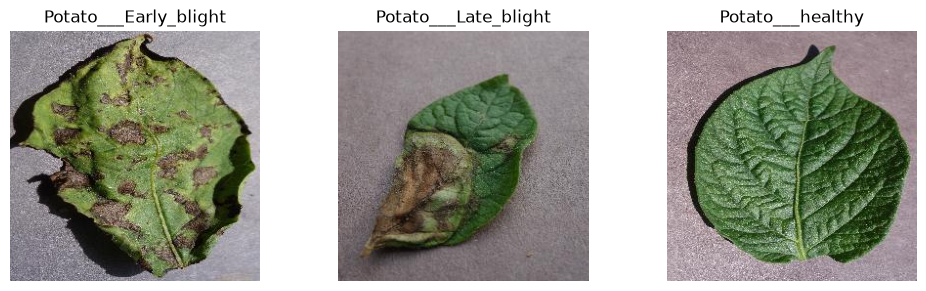

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
for i, name in zip(axes, classes):
    folder = DATA/name
    file=next(p for p in folder.iterdir() if p.suffix.lower() in [".jpg", ".jpeg", ".png"])
    with Image.open(file) as img:
        img = img.convert("RGB")
        i.imshow(img)
        i.set_title(name)
        i.axis("off")   
plt.tight_layout()
plt.show()
    

load images , resize , split  into train /validation

In [5]:
train_ds = tf.keras.utils.image_dataset_from_directory( DATA, validation_split=0.2,subset="training",seed=SEED, image_size=IMG_SIZE, batch_size=BATCH_SIZE,color_mode="rgb",label_mode="int")

val_ds = tf.keras.utils.image_dataset_from_directory( DATA, validation_split=0.2,subset="validation",seed=SEED, image_size=IMG_SIZE, batch_size=BATCH_SIZE,color_mode="rgb",label_mode="int")


class_names = train_ds.class_names

images , labels = next(iter(train_ds))

print("class order ", class_names)
print("images in one batch ", images.shape )
print("labels in one batch ", labels[:32].numpy()) 

Found 2152 files belonging to 3 classes.
Using 1722 files for training.
Found 2152 files belonging to 3 classes.
Using 430 files for validation.
class order  ['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']
images in one batch  (32, 128, 128, 3)
labels in one batch  [0 1 2 1 0 0 0 0 1 1 1 1 0 0 1 1 1 1 2 2 1 1 1 0 1 0 0 1 1 0 0 1]


data augmentation : rotation , zoom , horizontal flip , vertical flip  and scaling 

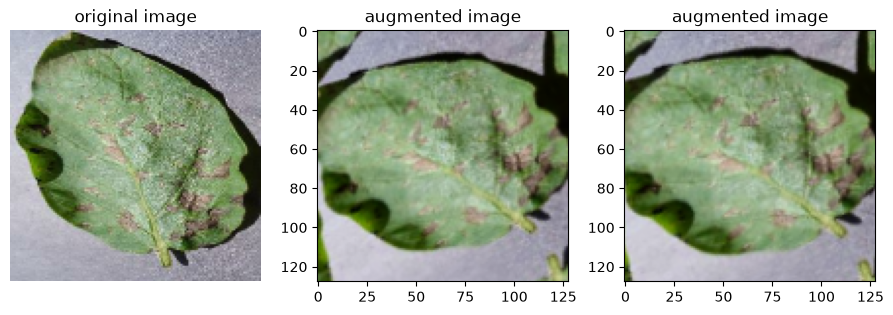

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

In [6]:
augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal_and_vertical"), 
    tf.keras.layers.RandomRotation(0.1,fill_mode="reflect"),                  
    tf.keras.layers.RandomZoom(height_factor=(-0.15, 0.0),fill_mode="reflect"), 
    tf.keras.layers.RandomContrast(0.1)                    
])

sample=images[0:1]
fig , axes = plt.subplots(1,3, figsize=(9,3))
axes[0].imshow(tf.cast(sample[0], tf.uint8 ))
axes[0].set_title("original image")

for i in (1,2):
    augmented=augmentation(sample,training=True)[0]
    axes[i].imshow(tf.cast(tf.clip_by_value(augmented, 0,255),tf.uint8))

    axes[i].set_title("augmented image") 

for i in axes:
    i.axis("off")
    plt.tight_layout()
    plt.show()
    



cnn layers : 1.feature_extractor(conv2d,maxpooling2d),2.(flatten),3.classifier(dense+dropout+softmax)

In [7]:
model=tf.keras.Sequential([
    tf.keras.Input(shape=(128,128,3)),
    tf.keras.layers.Rescaling(1.0/255),
    augmentation,

    #  feature extractor
    tf.keras.layers.Conv2D(32,3 , padding= "same", use_bias=False), 
    tf.keras.layers.BatchNormalization(momentum=0.9),
    tf.keras.layers.Activation("relu"),
    tf.keras.layers.MaxPooling2D(),


    tf.keras.layers.Conv2D(64,3 ,padding="same", use_bias=False),
    tf.keras.layers.BatchNormalization(momentum=0.9),
    tf.keras.layers.Activation("relu"),
    tf.keras.layers.MaxPooling2D(),



    tf.keras.layers.Conv2D(128,3 ,padding="same",use_bias=False ),
    tf.keras.layers.BatchNormalization(momentum=0.9),
    tf.keras.layers.Activation("relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(256,3 ,padding="same",use_bias=False ),
    tf.keras.layers.BatchNormalization(momentum=0.9),
    tf.keras.layers.Activation("relu"),
    tf.keras.layers.MaxPooling2D(),

    # flatten
    tf.keras.layers.GlobalAveragePooling2D(), 


    # classifier
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(3, activation="softmax")


])

model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴─────────────

 Total params: 423,139 (1.61 MB)

 Trainable params: 422,179 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

In [8]:
train_labels=np.concatenate([y.numpy() for _,y in train_ds])
class_counts=np.bincount(train_labels, minlength=len(class_names))

class_weights={i: len(train_labels)/(len(class_names)*count) for i,count in enumerate(class_counts)}

class_weights={i:float(np.sqrt(w)) for i, w in class_weights.items()  }

print("training class counts:", dict(zip(class_names, class_counts)))
print("class weights:", class_weights)

model.compile(optimizer=Adam(learning_rate=0.001), loss="sparse_categorical_crossentropy", metrics=['accuracy'])


#apply callback (model_checkpoints)

callbacks_list=[
    EarlyStopping(
        monitor='val_loss',
        patience=8,
        restore_best_weights=True,
        verbose=1

    ),

    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    )
]




history=model.fit(train_ds,validation_data=val_ds, epochs=40, class_weight=class_weights,callbacks=callbacks_list)


training class counts: {'Potato___Early_blight': np.int64(818), 'Potato___Late_blight': np.int64(792), 'Potato___healthy': np.int64(112)}
class weights: {0: 0.8376822138750128, 1: 0.8513210174472816, 2: 2.2638462845343543}
Epoch 1/40


d:\python\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


54/54 ━━━━━━━━━━━━━━━━━━━━ 56s 937ms/step - accuracy: 0.8902 - loss: 0.2684 - val_accuracy: 0.8093 - val_loss: 0.7388 - learning_rate: 0.0010
Epoch 2/40
54/54 ━━━━━━━━━━━━━━━━━━━━ 47s 874ms/step - accuracy: 0.9262 - loss: 0.2197 - val_accuracy: 0.8674 - val_loss: 0.4786 - learning_rate: 0.0010
Epoch 3/40
54/54 ━━━━━━━━━━━━━━━━━━━━ 48s 893ms/step - accuracy: 0.9390 - loss: 0.1618 - val_accuracy: 0.8744 - val_loss: 0.3085 - learning_rate: 0.0010
Epoch 4/40
54/54 ━━━━━━━━━━━━━━━━━━━━ 46s 844ms/step - accuracy: 0.9570 - loss: 0.1142 - val_accuracy: 0.9233 - val_loss: 0.2179 - learning_rate: 0.0010
Epoch 5/40
54/54 ━━━━━━━━━━━━━━━━━━━━ 42s 773ms/step - accuracy: 0.9559 - loss: 0.1143 - val_accuracy: 0.8767 - val_loss: 0.2886 - learning_rate: 0.0010
Epoch 6/40
54/54 ━━━━━━━━━━━━━━━━━━━━ 41s 749ms/step - accuracy: 0.9582 - loss: 0.1081 - val_accuracy: 0.8000 - val_loss: 0.5777 - learning_rate: 0.0010
Epoch 7/40
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 708ms/step - accuracy: 0.9541 - loss: 0.1248
Epoch 7

training and validation graphs

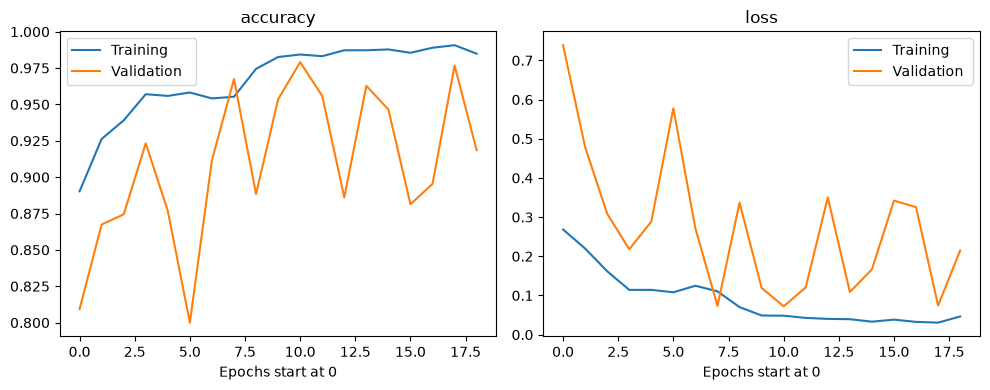

In [9]:
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Training  ') 
plt.plot(history.history['val_accuracy'], label='Validation  ')
plt.title('accuracy')
plt.xlabel('Epochs start at 0')
plt.legend()


plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Training ')
plt.plot(history.history['val_loss'], label='Validation ')
plt.title('loss')
plt.xlabel('Epochs start at 0')
plt.legend()    


plt.tight_layout()
plt.show()


confusion matrix and classification report

validation accuracy:0.98 not test accuracy


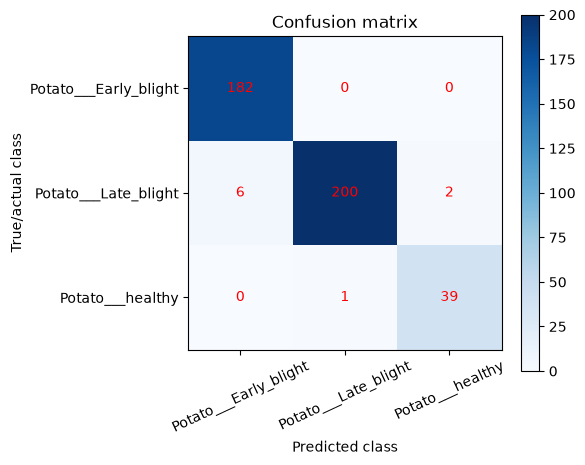

In [10]:
all_true,all_pred=[],[]
for batch_images,batch_labels in val_ds:
    scores=model.predict(batch_images,verbose=0)
    all_true.extend(batch_labels.numpy())
    all_pred.extend(np.argmax(scores,axis=1))

matrix=tf.math.confusion_matrix(all_true,all_pred,num_classes=len(class_names)).numpy()

accuracy=np.mean(np.array(all_true)==np.array(all_pred))
print(f"validation accuracy:{accuracy:.2f} not test accuracy")

plt.figure(figsize=(6,5))
plt.imshow(matrix, cmap="Blues")
plt.colorbar()

plt.xticks(range(3),[s.replace("potato__","") for s in class_names],rotation=25)
plt.yticks(range(3),[s.replace("potato__","") for s in class_names]) 
plt.xlabel("Predicted class")
plt.ylabel("True/actual class")
plt.title("Confusion matrix")  


for i in range(3):
    for j in range(3):
        plt.text(j,i, matrix[i,j], ha="center", va="center", color="red")
plt.tight_layout()
plt.show()
        


In [11]:
model.save("potato_cnn_model.keras")
Path("classification_report.txt").write_text("\n".join(class_names),encoding="utf-8")
print("model saved to potato_cnn_model.keras and class names saved to classification_report.txt")

model saved to potato_cnn_model.keras and class names saved to classification_report.txt


unseen data prediction and check accuracy

model score 1.00
Potato___Early_blight : 0.00
Potato___Late_blight : 0.00
Potato___healthy : 1.00


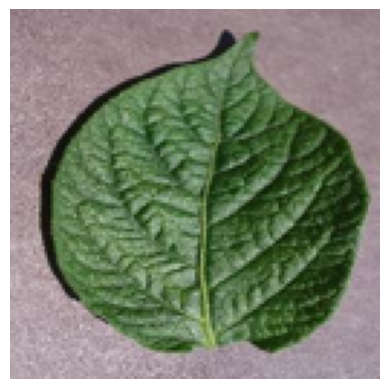

In [12]:
image_path = ROOT / "leaf.jpg"
if image_path.is_file():
    with Image.open(image_path) as file:
        image = file.convert("RGB").resize(IMG_SIZE)
    x=np.expand_dims(np.array(image,dtype=np.float32),axis=0)
    scores=model.predict(x,verbose=0)[0]
    best= int(np.argmax(scores))
    print("model score",f"{scores[best]:.2f}")
    for name, score in zip(class_names,scores):
        print(f"{name.replace('potato__','')} : {score:.2f}")
    plt.imshow(image)
    plt.axis("off")
    plt.show()
else:
    print(" place an image named leaf.jpg beside this notebook and run cell again")
                     

#hyperparametr tuning

dropout
learning_rate 
class_weight
epoch

batch normilization   
model_check_point     